**Objective**: This notebook introduces the initial Exploratory Data Analysis (EDA) process that was conducted, as well as the development of a baseline text classification model.

# 1. Exploratory Data Analysis

This first section will focus on the understanding of the data provided in order to get a global overview of it while also identifying potential patterns, imbalances or other factos that may influence the classification task at hand.

**Step 1:** Importing the necessary libraries and the dataset. It is important to note that only the training data will be imported since the test set will only be used for the classification of the final model and, therefore, it is not needed in this notebook.

In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [129]:
train_data = pd.read_csv("data/train.csv")

In [130]:
train_data.head()

,title,tag,artist,year,views,features,lyrics,id
0,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...,535805
1,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...,7519483
2,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...,4892808
3,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...,1584150
4,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...,7639050


**NOTE**: For the meaning of each feature, please refer to the *README.md* file.

**Step 2**: Understanding the structure of the dataset.

In [131]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   title     134965 non-null  str  
 1   tag       134967 non-null  str  
 2   artist    134967 non-null  str  
 3   year      134967 non-null  int64
 4   views     134967 non-null  int64
 5   features  134967 non-null  str  
 6   lyrics    134967 non-null  str  
 7   id        134967 non-null  int64
dtypes: int64(3), str(5)
memory usage: 8.2 MB


Based on the overview above, we can already identify some missing values (2) on the `title` column, with the remaining features complete (note that {} is a placeholder for missing features). This dataset has 134967 obvervations and 8 attributes, with 3 of them being numerical and the remaining 5 being string columns.

**Step 3**: Checking for duplicate `id`s.

In [132]:
train_data['id'].is_unique

True

There are no duplicates on the `id` column. Therefore, it can be set as the index of our dataframe.

In [133]:
train_data.set_index('id', inplace = True)

In [134]:
train_data

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\nDid you mean it th...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\n[Hook]\nEverybody wants you to...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\nPeople tell me I've changed\nI find...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\nDon't try to get ...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\nI can see the end is coming but I’v...
...,...,...,...,...,...,...,...
1702980,Manhattan,pop,Tijuana Sweetheart,2007,48,{},If I knew when I was young that I'd be older\n...
4802970,Belly Shit,rap,Lil Gotit,2019,3593,"{""Lil Troup""}",[Intro: Lil Gotit]\nCash\nWah-wah-wah\nWah-wah...
403929,The Four Loves,rock,Heath McNease,2014,301,{},[Verse 1]\nI was born inside a home\nThe young...


**Step 4**: Checking for duplicate songs on the dataset (same title, artist and lyrics).

In [135]:
bool(train_data.duplicated(subset=['title', 'artist', 'lyrics']).any())

False

**Step 5**: Analysing the target variable (`tag`).

In [136]:
tag_counts = train_data['tag'].value_counts()

display(tag_counts)
display(train_data['tag'].value_counts(normalize = True) * 100)

tag
pop        55742
rap        38584
rock       25332
rb          6203
misc        5640
country     3466
Name: count, dtype: int64

tag
pop        41.300466
rap        28.587729
rock       18.769032
rb          4.595938
misc        4.178799
country     2.568035
Name: proportion, dtype: float64

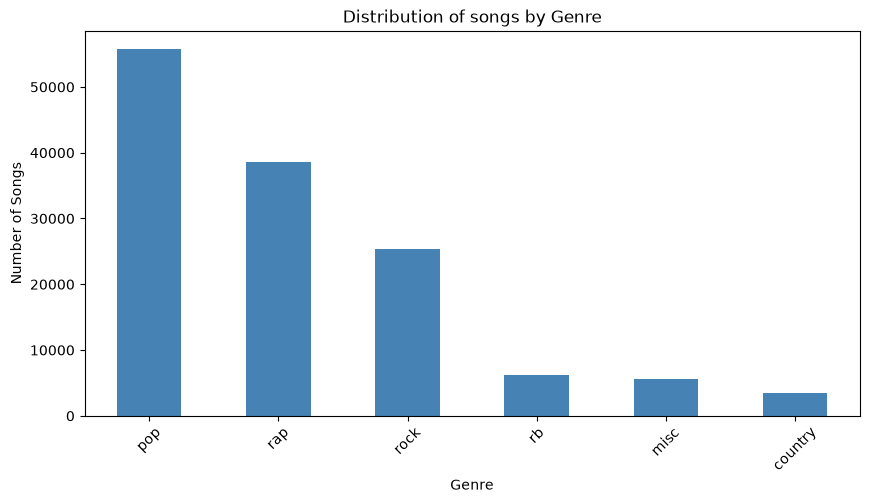

In [137]:
tag_counts.plot(kind = 'bar', figsize = (10,5), color = 'steelblue')

plt.xlabel('Genre')
plt.ylabel('Number of Songs')
plt.title('Distribution of songs by Genre')

plt.xticks(rotation = 45)
plt.show()

By analysing the ouput, we can see that the songs can be classified into **6** genres: **pop**, **rap**, **rock**, **R&B (rb)**, **miscellaneous (misc)** and **country**. The distribution of this genres across the dataset is imbalanced, with **pop** being the **most** frequent genre (41.3 %) and **country** the **least** frequent (only 2.57%). It is important to acknowledge this imbalance when dealing with a text classification task since the model might become biased towards the more representative class and fail to classify correctly the minority class. Therefore, the model evaluation process should consider metrics like the macro F1-score, instead of simply using the accuracy, to correctly assess performance across all genres.

**Step 6**: Analyse the numerical features.

In [138]:
train_data.describe()

,year,views
count,134967.000000,1.349670e+05
mean,2009.467537,3.413344e+03
std,46.287743,4.192449e+04
min,1.000000,0.000000e+00
25%,2008.000000,2.200000e+01
50%,2015.000000,8.900000e+01
75%,2019.000000,4.730000e+02
max,2024.000000,3.604497e+06


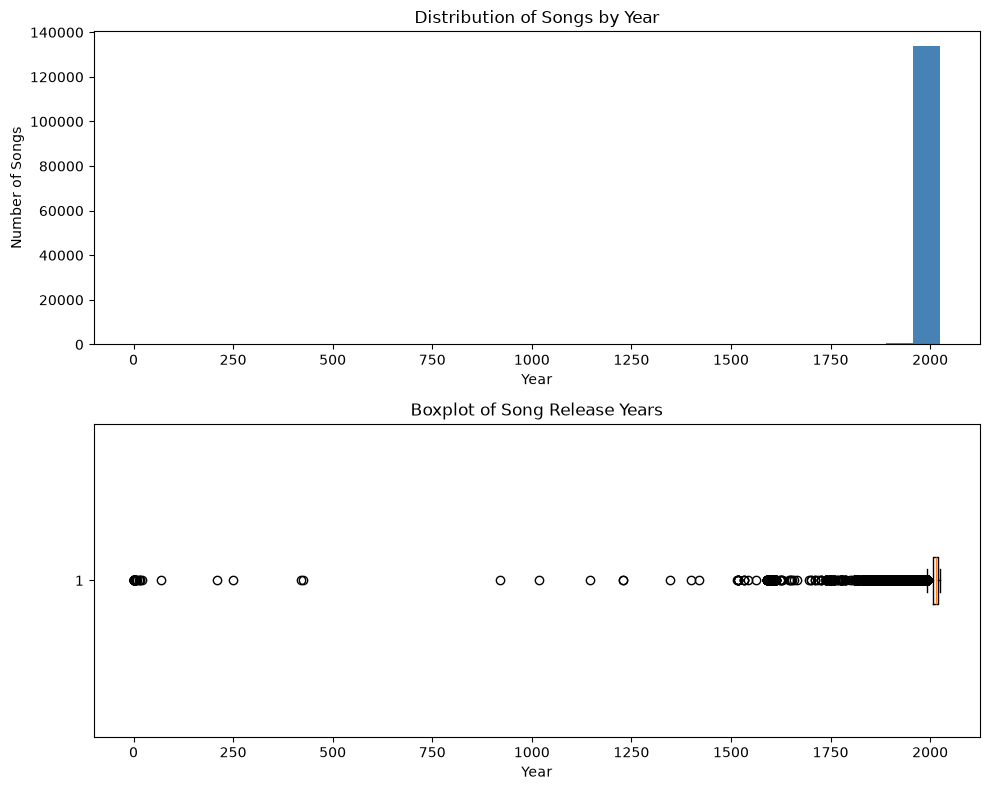

In [139]:
fig, axes = plt.subplots(2, 1, figsize = (10,8))

axes[0].hist(train_data['year'], bins = 30, color = 'steelblue')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Songs')
axes[0].set_title('Distribution of Songs by Year')

axes[1].boxplot(train_data['year'], vert = False)
axes[1].set_xlabel('Year')
axes[1].set_title('Boxplot of Song Release Years')

plt.tight_layout()
plt.show()

As we can see, there is an issue with the year column: there are some years that are invalid. These outliers will be treated as errors on the dataset.

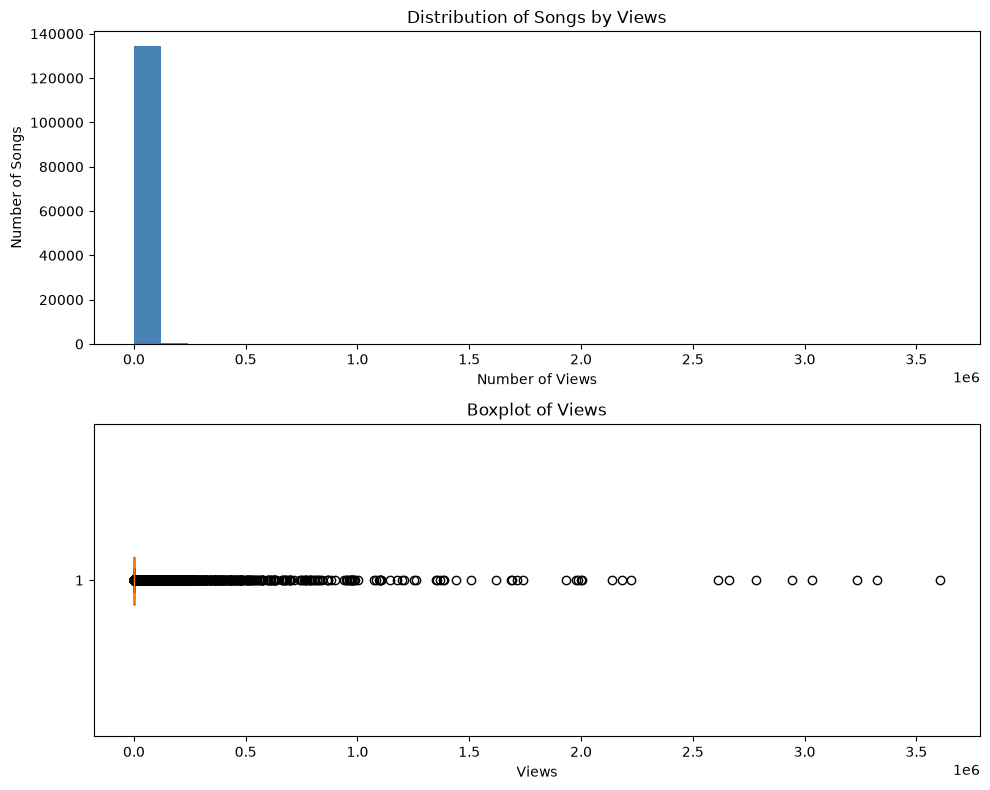

In [140]:
fig, axes = plt.subplots(2, 1, figsize = (10,8))

axes[0].hist(train_data['views'], bins = 30, color = 'steelblue')
axes[0].set_xlabel('Number of Views')
axes[0].set_ylabel('Number of Songs')
axes[0].set_title('Distribution of Songs by Views')

axes[1].boxplot(train_data['views'], vert = False)
axes[1].set_xlabel('Views')
axes[1].set_title('Boxplot of Views')

plt.tight_layout()
plt.show()

As we can see, the variable `views` is highly right-skewed (with some outliers on the right), with most songs having a low view count and few of them having a higher count (representing "hits" and high-performing tracks). To normalize this variance and to better understand the underlying pattern, we will apply a logarithmic transformation to observe the plot again.

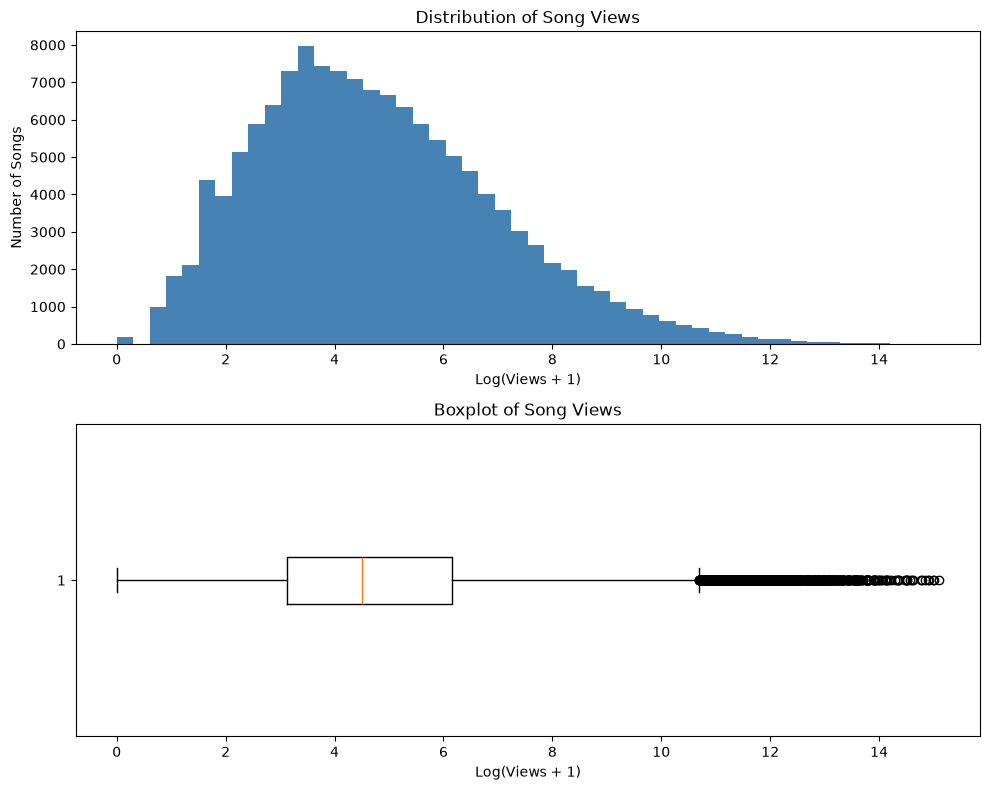

In [141]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# log1p instead of log bc there are songs with 0 views
axes[0].hist(np.log1p(train_data['views']), bins=50, color='steelblue') 
axes[0].set_title('Distribution of Song Views')
axes[0].set_xlabel('Log(Views + 1)')
axes[0].set_ylabel('Number of Songs')


axes[1].boxplot(np.log1p(train_data['views']), vert = False)
axes[1].set_title('Boxplot of Song Views')
axes[1].set_xlabel('Log(Views + 1)')

plt.tight_layout()
plt.show()

By analysing the plot above, we can see that the histogram now presents a unimodal distribution, with the main peak centered near 4 (which corresponds to nearly 54 views). It is also possible to conclude that the 50% of the songs have log(views + 1) between 3 and 6 (corresponding to between 19 and 402 views).

**Step 7**: Checking all the invalid years on the `year` column.

In [142]:
with pd.option_context('display.max_rows', None): # to display more rows
    display(train_data['year'].value_counts().sort_index())

year
1          45
3           1
4           1
6           1
7           1
9           1
14          1
17          2
22          1
69          1
210         1
250         1
420         1
426         1
920         1
1017        1
1145        1
1228        2
1347        1
1400        1
1420        1
1516        1
1517        6
1532        3
1542        1
1563        1
1590        9
1591        3
1593        4
1594        1
1595        7
1597        3
1598        1
1599        2
1600        3
1601        1
1602        5
1603        4
1604        3
1606        1
1608        1
1609        9
1610        2
1611        2
1612        3
1613        1
1614        2
1623        2
1625        1
1629        2
1645        1
1647        1
1650        1
1653        1
1657        1
1666        1
1697        1
1700        2
1712        2
1719        1
1726        3
1738        6
1742        4
1744        1
1748        1
1749        9
1751        4
1754        3
1759        7
1766        2
1771        1
1

Let's further inspect all the songs that were released earlier than 1500.

In [145]:
year_col = train_data['year']
cols = ['title', 'artist', 'tag', 'year', 'lyrics']
with pd.option_context('display.max_rows', None): # to display more rows
    display(train_data[year_col < 1500][cols])               
print(train_data[year_col.between(1, 1500)]['tag'].value_counts())   

,title,artist,tag,year,lyrics
id,,,,,
7639050,Get Ready,John Campbell Munro,country,1,[Verse 1]\nI can see the end is coming but I’v...
2393721,Parks n Wreck,Joshy Raps,rap,6,"All the same height, same size, same level but..."
7252806,Insecure,Taylor Stannard,pop,69,(verse one)\n\nI’m not afraid to suck your bal...
113408,Acts 3,Holy Bible (KJV),misc,1,Acts 3:1: Now Peter and John went up together ...
7361529,Lake Michigan,DON KEL,rap,1,I don't fuck with many n**** (Woah)\nI be on m...
7309289,Hate Love,Rivers Ventura,pop,22,Run around over town on the first date\nAnd I ...
6905467,Secondhand Clothes,Maker of the Bear,rock,1,Verse 1\nI was talking to myself\nFull of fear...
6125089,ADW,Lik2ss,rap,1,"Intro : 2ss! 2ss\n42uce DreamTeam Nigga, Free ..."
3836184,Woop,Lxrry,rap,1,[Intro]: Lxrry\nWe taking over like woop\n\nWe...


tag
rap        30
misc       16
pop        10
rb          6
rock        4
country     1
Name: count, dtype: int64


As we just verified, there are 45 songs with the `year` variable equal to 1, so the approach we decided on was to treat the value 1 as a missing value.

In [58]:
train_data['year'] = train_data['year'].replace(1, np.nan)

**Step 7**: Analysing the categorical variables.

In [28]:
train_data.describe(include='O')

,title,tag,artist,features,lyrics
count,134965,134967,134967,134967,134967
unique,107703,6,74916,18389,134789
top,Intro,pop,Genius English Translations,{},Tell us that you would like to have the lyrics...
freq,135,55742,555,111928,8


For the features variable, as verified before, the {} is a placeholder for missing values. Therefore, those will be treated as missing values.

In [29]:
train_data['features'] = train_data['features'].replace('{}', np.nan)

As for the `lyrics` variable, the most frequent value does not contain actual song lyrics; it is actually a placeholder indicating that the actual lyrics of the song are unavailable. As such, we will treat them as missing lyrics.

In [33]:
train_data[train_data.duplicated(subset=['lyrics'], keep=False)]

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
5993362,The Art Show Demo,rock,Significantly,2020.0,7,NaN,It's my turn to make a move\nI'll smile to hid...
1561623,Free,pop,Kevin Mahogany,1997.0,277,NaN,Mya you know the hook\nYou see the bait\nI kno...
2074480,The Feeling That We Have,pop,Theresa merritt,1978.0,396,NaN,Put your arms around me child\nLike when you b...
1821215,This Is Why Im Hot remix instrumental feat. Ju...,pop,M.I.M.S,2015.0,116,NaN,This is why I'm hot\nThis is why I'm hot\nThis...
2670235,Love Yourself,rock,The Maine,2016.0,1411,NaN,[Verse 1]\nFor all the times that you rained o...
...,...,...,...,...,...,...,...
1843064,In My Arms Bimbo Jones extended mix,pop,Plumb,2015.0,201,NaN,Your baby blues\nSo full of wonder\nYour curly...
2339574,Macklemore and Ryan Lewis’s “Wing$” 2,rap,TeachSkogs,2015.0,7,NaN,[Verse 1]\nI was seven years old\nWhen I got m...
859758,Jubilation This Thing Called Life K.C.s Camp P...,pop,Anything Box,2015.0,19,NaN,Every time I close my eyes\nI hide behind the ...


In [33]:
train_data['lyrics'].value_counts().head(1)

lyrics
Tell us that you would like to have the lyrics of this song. Then we'll make it our highest priority to find these lyrics first!\nOr perhaps you can help us out. If you have the lyrics of this song, it would be great if you can submit these. That will definitely help us and the other visitors!    8
Name: count, dtype: int64

In [ ]:
placerholder_lyrics = train_data['lyrics'].value_counts().head(1).index[0] # extracting the exact text

train_data.loc[train_data['lyrics'].str.contains(placerholder_lyrics), 'lyrics'] = pd.NA

**Step 8**: Checking the missingness of the dataset again.

In [37]:
display(train_data.isna().sum())
display(train_data.isna().sum() / len(train_data) * 100)

title            2
tag              0
artist           0
year            45
views            0
features    111928
lyrics           8
dtype: int64

title        0.001482
tag          0.000000
artist       0.000000
year         0.033341
views        0.000000
features    82.929901
lyrics       0.005927
dtype: float64

As we verify, the `features` variable is mostly composed of missing values (nearly 83%) so we decided to drop this column for further analysis, since it does not contain any information that the model can use.

In [38]:
train_data = train_data.drop(columns = ['features'])

Furthermore, and since the purpose of the project is to classify songs into genres based on song lyrics, the rows which have missing lyrics will be dropped.

In [39]:
train_data = train_data.dropna(subset=['lyrics'])

The remaining missing values will be kept as missing for now.